# Case Study 15 — "Customers Who Bought This Also Bought": Item-to-Item Collaborative Filtering, Cold Start, Popularity Bias and the Offline–Online Gap

**Priority:** ★★★ Must-visit · **Reference:** Case Study 15 — *Amazon: item-to-item collaborative filtering* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Personalisation, Product (home page, product page, cart), Growth, Finance
**Data:** ⚠️ **SYNTHETIC** (D-15-01). Purchase logs are confidential; this is a calibrated simulation with a hidden "true taste" model.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs15_item_to_item_collaborative_filtering.ipynb`

## 0. Executive Summary for Business

*(Synthetic purchases with a hidden taste model, built on the documented design of Amazon's item-to-item collaborative filtering: similar-item tables computed offline and looked up online, working from as few as two or three items. Amazon's data and results are not reproduced; the 2003 paper reports no metric tables. Written after the analysis.)*

- **The question:** what should we show as "customers also bought", how much better is item-to-item filtering than best-sellers and the alternatives, and how would we know in an A/B test?
- **Item-to-item filtering wins on this data.** Its **hit rate at 10 is 19.7%** (95% CI 19.1% to 20.4%), against **11.2% for best-sellers**, 16.6% for user-based filtering, 13.6% for matrix factorisation and 17.3% for sequence-aware co-purchase. Every gap is significant on the same customers (McNemar, Holm p < 1e-4). Its NDCG@10 is 0.113 against 0.061 for best-sellers.
- **It works for customers with little history, but the advantage grows with history.** For customers with 1 to 3 purchases, item-to-item beats best-sellers by only **27%** (18.1% vs 14.3%), and is close to user-based filtering (17.4%). With 10 or more purchases the lift is **2.0×** (interaction test p = 1.3e-7). Best-sellers is a strong baseline for new customers.
- **Popularity bias is real.** Item-to-item recommends popular items (mean log-popularity 6.3 vs 5.2 for the damped version) and hits **41% of head items but only 3.8% of tail items**. Damping popularity **lowers the hit rate to 14.3%**, but it lifts tail-item hits to 5.9%, catalogue coverage from 72% to 90% and lowers exposure inequality (Gini 0.95 to 0.84).
- **Accessory pairs need the sequence.** For purchases that completed an accessory pair (n = 112), the sequence-aware method hits **70%** against 27% for item-to-item and 1% for best-sellers.
- **Offline and online agree here, roughly.** Against the digital twin's expected click rate, the ranking correlation is **+0.89** and item-to-item is best both ways. The order of the middle methods changes (user-based is second online but third offline), so offline accuracy alone is a weak guide for close calls.
- **Scaling:** at this small size the similarity step grows roughly **linearly or slower with customers** and about **N^1.5 with items**. That does not confirm Amazon's "closer to O(NM)" claim for items, but our catalogue is tiny.
- **Money (assumed click model):** about **₹73 crore a year** over best-sellers at 1 crore impressions a day (CI 72 to 75). The level depends on the twin's assumed click rates, so rely on the ranking more than the rupee figure.
- **A/B test:** a **10% relative lift in click rate** needs about **10,600 impressions per arm**, or **1,500 customers** after allowing for repeat impressions.
- **I recommend:** make item-to-item the default candidate generator, add a sequence-aware list for accessories, apply a **light popularity damping on discovery surfaces only**, and confirm with a live A/B test before rollout.

## 1. The Problem in Simple English

Every ecommerce app shows "**Customers who bought this also bought…**" and "**Recommended for you**". With millions of customers and millions of products, it has to pick a handful of items in a few milliseconds for each person. Amazon's 2003 paper gave the answer that is still the default building block: instead of finding customers *similar to you* (millions of comparisons, slow, and unstable), find **items similar to the ones you already bought**. Item-to-item similarity can be **computed overnight** and looked up instantly. It also works when you have bought only **two or three items**.

Leaders and interviewers want to know:
1. How much better is it than just showing **best-sellers**?
2. How does it compare with **customer-based** methods and **matrix factorisation**?
3. Does it work for **new customers** with little history, and for **new or niche items**?
4. Does it just recommend **popular items** (popularity bias)?
5. Why can **offline accuracy** disagree with what happens in an **A/B test**?

## 2. Reference from the Case File

### (a) What Amazon did — *documented*

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | Real-time personalised recommendations over a very large catalogue and customer base. The paper states Amazon had "more than 29 million customers and several million catalog items", and notes earlier algorithms were tested on much smaller data such as MovieLens (35,000 customers, 3,000 items) |
| Question | How to generate recommendations in real time, with good quality even for customers with little history, at a scale where classic user-based CF breaks? |
| Approach | Offline: build a **similar-items table** by finding items customers tend to buy together; similarity per item pair, typically **cosine** over the customers who bought each. Online: for each item the user bought or rated, look up similar items, aggregate and recommend the most popular or correlated. The paper contrasts traditional CF (compares a user with many customers), cluster models (cheap but lower quality) and search-based methods |
| Complexity | Offline worst case O(N²M), "closer to O(NM) in practice"; online lookup depends only on the number of items the user has purchased or rated |
| Evidence limits | The paper is qualitative on quality: **no metric tables and no revenue figures** (validation, impact: ND). Works "based on as few as two or three items" |

**Source:** Linden, Smith & York, "Amazon.com Recommendations: Item-to-Item Collaborative Filtering", IEEE Internet Computing, Jan/Feb 2003 (read through a text-extraction proxy).

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 15,000 customers × 2,500 items (25 categories) over 180 days, ≈ 166,000 purchases (density 0.4%). Taste is latent (12 dimensions), popularity is long-tailed, 120 accessory pairs ("phone → case") are bought together within a week with probability 0.18, and 15% of customers have 3 or fewer purchases. |
| Methods compared | (1) Best-sellers; (2) **user-based CF** (kNN, cosine); (3) **item-to-item CF** (Amazon's method, top-50 neighbour table); (4) item-to-item with **popularity damping**; (5) **truncated-SVD matrix factorisation**; (6) **sequence-aware co-purchase** ("bought j within a week after i") |
| Statistics added | Leave-last-out evaluation (HR@10, NDCG@10, MRR); **McNemar** and **paired bootstrap/Wilcoxon** per user (Holm); results by history length (cold start); **head vs tail items**; coverage and exposure **Gini**; **digital-twin online test** to compare offline and online rankings; **runtime scaling** (the O(NM) claim); A/B sample size |

### (c) How the industry uses this

"Customers also bought" and "similar items" are on every Indian marketplace and quick-commerce app (Amazon, Flipkart, Myntra, Meesho, Swiggy Instamart "add more"). The **item-to-item table plus ranking model on top** is the standard architecture; matrix factorisation and neural two-tower models are used for the candidate-generation step. It is among the most-asked ecommerce interview topics: similarity measures, sparsity, cold start, popularity bias, offline vs online evaluation.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | What should we recommend to each customer, and how do we know a new recommender is really better? |
| Analytical | Which method best predicts each customer's next purchase out of time, for whom (cold start, tail items), and does the offline winner also win online? |

**Hypotheses**
- **H1:** H0: item-to-item CF's hit rate at 10 equals best-sellers' (McNemar on the same users).
- **H2:** H0: item-to-item CF equals user-based CF and SVD in NDCG@10 (paired bootstrap / Wilcoxon; Holm).
- **H3 (cold start):** H0: item-to-item CF's advantage over best-sellers is the same for customers with 1–3 items as for those with 10+ (interaction test).
- **H4 (online):** H0: the offline ranking of methods equals their ranking in a twin online test (Spearman).

**Primary metrics:** **HR@10** and **NDCG@10** on each customer's **last purchase** (held out in time). **Diagnostic metrics:** catalogue **coverage**, **exposure Gini**, mean log-popularity of recommendations. **Online proxy:** expected CTR of the top 10 under the hidden true-taste model.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public Indian ecommerce purchase logs | **None.** Public sets (Instacart, Retailrocket, Amazon reviews, MovieLens) are US/other, several are Kaggle-hosted, and none has a known true-taste model. |
| **Decision** | Synthetic purchases with hidden taste and popularity, so that offline and "online" evaluation can both be run (D-15-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs15.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 15 (Amazon-style item-to-item collaborative filtering)
===========================================================================================
THIS DATA IS SYNTHETIC. Marketplace purchase logs are confidential.

Documented context (Linden, Smith & York, IEEE Internet Computing 2003): >29 million customers, several million
items, very sparse customer-item vectors, item-to-item similarity computed offline and looked up online, works
"from as few as two or three items". Prior CF was tested on MovieLens-size data (35,000 customers, 3,000 items).

Simulation: 15,000 customers x 2,500 items in 25 categories over 180 days.
  * Taste: each customer has a 12-dim latent taste vector, each item a latent vector near its category centre.
  * Popularity: a long-tailed item popularity term (a few best-sellers; most items rarely bought).
  * Complements: 120 "accessory" pairs (phone -> case) bought within a week with probability 0.18.
  * Purchases per customer ~ negative binomial (mean 11), so many customers have only 2-4 purchases (cold start).
Hidden truth for a DIGITAL-TWIN online test: true click probability = sigmoid(taste affinity + popularity effect).

Outputs: data/cs15/purchases.csv.gz, data/cs15/items.csv.gz, data/cs15/true_params.npz
"""
import os
import numpy as np
import pandas as pd

SEED = 42
START = pd.Timestamp("2026-01-01"); DAYS = 180
N_U, N_I, N_CAT, K = 15_000, 2_500, 25, 12


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    cat = rng.integers(0, N_CAT, N_I); centre = rng.normal(0, 1.0, (N_CAT, K))
    V = centre[cat] + rng.normal(0, 0.45, (N_I, K)); pop = rng.pareto(1.3, N_I) + 1; logpop = np.log(pop); logpop = (logpop - logpop.mean()) / logpop.std()
    U = np.zeros((N_U, K)); fav = rng.integers(0, N_CAT, (N_U, 2)); U = 0.75 * centre[fav[:, 0]] + 0.45 * centre[fav[:, 1]] + rng.normal(0, 0.55, (N_U, K))
    n_p = np.maximum(1, rng.negative_binomial(2.2, 2.2 / (2.2 + 11), N_U)); n_p = np.minimum(n_p, 80)
    acc_src = rng.choice(N_I, 120, replace=False); acc_dst = rng.choice(N_I, 120, replace=False)
    rows = []; ratio = 0.9
    for lo in range(0, N_U, 1500):
        hi = min(N_U, lo + 1500); S = 1.1 * (U[lo:hi] @ V.T) / np.sqrt(K) + ratio * logpop[None, :]; S -= S.max(1, keepdims=True); P = np.exp(S); P /= P.sum(1, keepdims=True)
        for k, u in enumerate(range(lo, hi)):
            items = rng.choice(N_I, size=n_p[u], replace=False, p=P[k]); times = np.sort(rng.integers(0, DAYS, n_p[u]))
            for it, t in zip(items, times): rows.append((u, it, t, 0))
    df = pd.DataFrame(rows, columns=["user", "item", "day", "complement"])
    # complement purchases: after buying an accessory source, buy its partner within a week with probability 0.18
    m = dict(zip(acc_src, acc_dst)); add = []
    for u, it, t in zip(df.user.values, df.item.values, df.day.values):
        if it in m and rng.random() < 0.18: add.append((u, m[it], min(DAYS - 1, t + rng.integers(0, 7)), 1))
    df = pd.concat([df, pd.DataFrame(add, columns=df.columns)], ignore_index=True).drop_duplicates(["user", "item"]).sort_values(["user", "day"]).reset_index(drop=True)
    df["order_ts"] = START + pd.to_timedelta(df.day, unit="D") + pd.to_timedelta(rng.integers(8 * 3600, 23 * 3600, len(df)), unit="s")
    items = pd.DataFrame({"item": np.arange(N_I), "category": cat, "list_price_inr": np.round(np.exp(rng.normal(np.log(700), 1.0, N_I)), 0), "_log_pop_z": logpop})
    # data-quality defects
    dup = df.sample(n=4000, random_state=seed); bots = pd.DataFrame({"user": N_U, "item": rng.choice(N_I, 800, replace=False), "day": rng.integers(0, DAYS, 800), "complement": 0}); bots["order_ts"] = START + pd.to_timedelta(bots.day, unit="D")
    df = pd.concat([df, dup, bots], ignore_index=True)
    return df, items, dict(U=U, V=V, logpop=logpop, acc_src=acc_src, acc_dst=acc_dst, ratio=ratio)


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs15"), exist_ok=True)
    d, it, tp = generate(); d.to_csv(os.path.join(here, "cs15", "purchases.csv.gz"), index=False); it.to_csv(os.path.join(here, "cs15", "items.csv.gz"), index=False); np.savez(os.path.join(here, "cs15", "true_params.npz"), **tp)
    dd = d.drop_duplicates(["user", "item"]); c = dd.groupby("user").size(); print(len(dd), "interactions |", c.describe()[["mean", "50%", "max"]].round(1).to_dict(), "| density", round(len(dd) / (N_U * N_I), 5), "| users with <=3", (c <= 3).mean().round(3))
    print("top-1% items share of purchases", dd.item.value_counts().head(25).sum() / len(dd))

Overwriting data/generate_cs15.py


In [3]:
os.makedirs("data/cs15", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs15 as gen; importlib.reload(gen)
t0 = time.time(); raw, items, TP = gen.generate(seed=SEED); raw.to_csv("data/cs15/purchases.csv.gz", index=False); items.to_csv("data/cs15/items.csv.gz", index=False)
print(f"{len(raw):,} purchase rows | {raw.drop_duplicates(['user', 'item']).shape[0]:,} unique user-item pairs | generated in {time.time() - t0:.0f}s")
raw.head(4)

170,470 purchase rows | 166,470 unique user-item pairs | generated in 64s


,user,item,day,complement,order_ts
0,0,2071,18,0,2026-01-19 08:37:41
1,0,501,32,0,2026-02-02 12:28:25
2,0,858,33,0,2026-02-03 16:24:43
3,0,2022,34,0,2026-02-04 19:29:18


| Parameter | Value | Basis |
|---|---|---|
| Scale | 15,000 customers, 2,500 items, 180 days | Our assumption (Amazon: 29M customers, several million items) |
| Taste | 12-dim latent vectors; customers favour 2 categories | Our assumption |
| Popularity | Pareto-tailed item popularity; top 1% of items ≈ 20% of purchases | Typical ecommerce long tail |
| Purchases | NB, mean ≈ 11 (median 9); 15% of customers have ≤ 3 | **Documented** concern for "as few as two or three items" |
| Complements | 120 accessory pairs, 18% bought within 7 days | Our assumption |
| Online twin | Click probability = sigmoid(−7.0 + taste affinity + popularity effect) | Our assumption (hidden truth) |
| DQ issues | 4,000 duplicate rows; one bot account with 800 purchases | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("purchases: user, item, day, order_ts", "Customer, item, day 0–179, timestamp"), ("complement", "1 if the purchase followed an accessory pairing (simulation flag)"),
    ("items: item, category, list_price_inr", "Item attributes"), ("_log_pop_z, true_params.npz", "HIDDEN: popularity, latent taste vectors (digital twin only)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs15/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"purchases: user, item, day, order_ts","Customer, item, day 0–179, timestamp"
1,complement,1 if the purchase followed an accessory pairin...
2,"items: item, category, list_price_inr",Item attributes
3,"_log_pop_z, true_params.npz","HIDDEN: popularity, latent taste vectors (digi..."


## 5. Data Quality Checks

In [5]:
cnt = raw.drop_duplicates(["user", "item"]).groupby("user").size(); thr = cnt.median() * 20
checks = {"duplicate user-item rows": int(raw.duplicated(["user", "item"]).sum()), "bot-like users (> 20× median purchases)": int((cnt > thr).sum()), "purchases by the bot": int(cnt[cnt > thr].sum())}
print(pd.Series(checks, name="rows").to_string())
bots = cnt[cnt > thr].index; df = raw.drop_duplicates(["user", "item"]); df = df[~df.user.isin(bots)].sort_values(["user", "day", "item"]).reset_index(drop=True)
NU, NI = gen.N_U, gen.N_I; per = df.groupby("user").size()
print(f"\nClean: {len(df):,} purchases | {df.user.nunique():,} customers | {df.item.nunique():,} items | density {len(df) / (NU * NI):.3%} | median purchases {per.median():.0f} | customers with ≤ 3 purchases: {(per <= 3).mean():.1%}")

duplicate user-item rows                   4000
bot-like users (> 20× median purchases)       1
purchases by the bot                        800



Clean: 165,670 purchases | 15,000 customers | 2,500 items | density 0.442% | median purchases 9 | customers with ≤ 3 purchases: 15.5%


**Observation:** we removed **4,000 duplicate user-item rows** and **one bot-like account** (800 purchases, over 20× the median). The clean data has **165,670 purchases from 15,000 customers across 2,500 items**, a density of **0.44%**, a median of 9 purchases per customer and **15.5% of customers with 3 or fewer**. The customer-item matrix is very sparse, which is the setting item-to-item filtering was designed for.

## 6. Exploratory Data Analysis

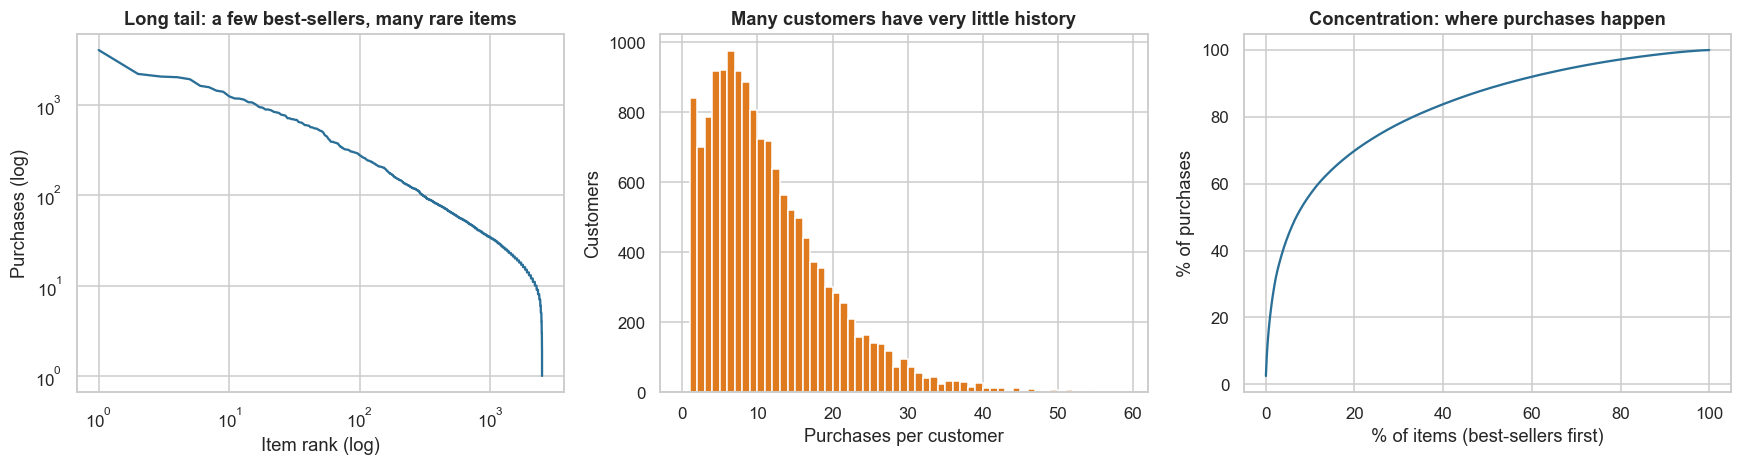

Top 1% of items = 21.0% of purchases; top 20% = 69.9%; items never purchased: 0


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
ip = df.item.value_counts().reindex(range(NI), fill_value=0).sort_values(ascending=False).values
axes[0].plot(np.arange(1, NI + 1), ip, color="#2a6f97"); axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlabel("Item rank (log)"); axes[0].set_ylabel("Purchases (log)"); axes[0].set_title("Long tail: a few best-sellers, many rare items")
axes[1].hist(per, bins=np.arange(0, 60), color="#e07a1f"); axes[1].set_xlabel("Purchases per customer"); axes[1].set_ylabel("Customers"); axes[1].set_title("Many customers have very little history")
cum = np.cumsum(ip) / ip.sum(); axes[2].plot(np.arange(1, NI + 1) / NI * 100, cum * 100, color="#2a6f97"); axes[2].set_xlabel("% of items (best-sellers first)"); axes[2].set_ylabel("% of purchases"); axes[2].set_title("Concentration: where purchases happen")
plt.tight_layout(); plt.show()
print(f"Top 1% of items = {cum[int(0.01 * NI)] * 100:.1f}% of purchases; top 20% = {cum[int(0.2 * NI)] * 100:.1f}%; items never purchased: {(ip == 0).sum()}")

**Takeaway:** purchases are **concentrated**: the top 1% of items account for **21%** of purchases and the top 20% for **70%**, yet every item sells at least once. Many customers have little history. A recommender that only repeats best-sellers would ignore most of the catalogue, and one that relies on a customer's own history would have little to work with for the 15% with three or fewer purchases.

## 7. Statistical Analysis (core section)

### 7.1 Setup: leave-last-out, five recommenders

**Evaluation protocol:** for every customer with ≥ 2 purchases, the **last purchase (by time)** is the test item; everything before it is training. This respects time order (no peeking at the future). A recommender returns 10 items the customer has not bought. **HR@10** = hit if the test item is in the list; **NDCG@10** rewards ranking it higher; **MRR** = 1/rank.

| # | Method | In one line |
|---|---|---|
| 1 | Best-sellers | The 10 most-bought items overall |
| 2 | User-based CF | Find the 50 most similar customers (cosine), recommend what they bought |
| 3 | **Item-to-item CF (Amazon)** | Cosine similarity between item purchase vectors; keep each item's 50 nearest items; sum the neighbours of the customer's items |
| 4 | Item-to-item, popularity-damped | As 3, but divide the final scores by (item popularity + 10)^0.3, to stop best-sellers dominating |
| 5 | Matrix factorisation | Truncated SVD (32 factors) of the customer × item matrix |
| 6 | Sequence-aware co-purchase | P(buy j within 7 days after i) counts: captures "accessory" pairs |

#### Code

In [7]:
last = df.groupby("user").tail(1); hist = df.drop(last.index); users = last.user.values; test_item = last.item.values
X = sparse.csr_matrix((np.ones(len(hist)), (hist.user.values, hist.item.values)), shape=(NU, NI)); nh = np.asarray(X.sum(1)).ravel()
keep = nh[users] >= 1; users, test_item = users[keep], test_item[keep]; pop = np.asarray(X.sum(0)).ravel()
print(f"Evaluation customers: {len(users):,} | training purchases {X.nnz:,}")
def ev_scores(S_fn, chunk=3000):
    out = np.zeros((len(users), 10), int)
    for lo in range(0, len(users), chunk):
        u = users[lo:lo + chunk]; sc = S_fn(u); sc = np.asarray(sc.todense()) if sparse.issparse(sc) else np.asarray(sc, float); sc[X[u].toarray() > 0] = -1e9
        idx = np.argpartition(-sc, 10, axis=1)[:, :10]; o = np.argsort(-np.take_along_axis(sc, idx, 1), axis=1); out[lo:lo + chunk] = np.take_along_axis(idx, o, 1)
    return out
t = {}; REC = {}
# 1 best-sellers
t0 = time.time(); REC["1 best-sellers"] = ev_scores(lambda u: np.tile(pop, (len(u), 1)).astype(float) + np.random.default_rng(0).random((len(u), NI)) * 1e-3); t["1 best-sellers"] = time.time() - t0
# 2 user-based CF
t0 = time.time(); Xn = normalize(X, axis=1)
def ub(u, k=50):
    sim = (Xn[u] @ Xn.T).toarray(); sim[np.arange(len(u)), u] = 0; idx = np.argpartition(-sim, k, axis=1)[:, :k]; w = np.take_along_axis(sim, idx, 1)
    W = sparse.csr_matrix((w.ravel(), (np.repeat(np.arange(len(u)), k), idx.ravel())), shape=(len(u), NU)); return W @ X
REC["2 user-based CF (k = 50)"] = ev_scores(ub, 1500); t["2 user-based CF (k = 50)"] = time.time() - t0
# 3 item-to-item CF: cosine, top-50 neighbours per item
t0 = time.time(); Xc = normalize(X, axis=0); S = (Xc.T @ Xc).toarray(); np.fill_diagonal(S, 0)
def topn_table(S, n=50):
    idx = np.argpartition(-S, n, axis=1)[:, :n]; rows = np.repeat(np.arange(S.shape[0]), n); return sparse.csr_matrix((np.take_along_axis(S, idx, 1).ravel(), (rows, idx.ravel())), shape=S.shape)
T3 = topn_table(S); t["build item-item table"] = time.time() - t0
REC["3 item-to-item CF (Amazon, top-50)"] = ev_scores(lambda u: X[u] @ T3);
# 4 popularity-damped
DAMP = (pop + 10) ** 0.3; REC["4 item-to-item, popularity-damped"] = ev_scores(lambda u: np.asarray((X[u] @ T3).todense()) / DAMP[None, :])
# 5 SVD
t0 = time.time(); svd = TruncatedSVD(32, random_state=SEED).fit(X); Uf = svd.transform(X); Vf = svd.components_; REC["5 matrix factorisation (SVD-32)"] = ev_scores(lambda u: Uf[u] @ Vf); t["5 SVD"] = time.time() - t0
# 6 sequence-aware co-purchase within 7 days
t0 = time.time(); h = hist.copy(); pairs = h.merge(h, on="user", suffixes=("_a", "_b")); pairs = pairs[(pairs.item_a != pairs.item_b) & (pairs.day_b >= pairs.day_a) & (pairs.day_b - pairs.day_a <= 7)]
SQ = sparse.csr_matrix((np.ones(len(pairs)), (pairs.item_a.values, pairs.item_b.values)), shape=(NI, NI)); SQ = SQ.multiply(1 / np.maximum(pop, 1)[:, None] ** 0.5).tocsr(); T6 = topn_table(SQ.toarray())
REC["6 sequence-aware co-purchase (7 days)"] = ev_scores(lambda u: X[u] @ T6); t["6 sequence"] = time.time() - t0
def metrics(rec):
    hit = (rec == test_item[:, None]); h = hit.any(1); pos = np.where(h, hit.argmax(1) + 1, 0)
    return h.astype(int), np.where(h, 1 / np.log2(pos + 1), 0.0), np.where(h, 1.0 / np.maximum(pos, 1), 0.0)
M = {k: metrics(r) for k, r in REC.items()}
rows = []
for k, (hh, nd, mr) in M.items():
    rec = REC[k]; lo, hi = proportion_confint(hh.sum(), len(hh), method="wilson"); cov = len(np.unique(rec)) / NI; counts = np.bincount(rec.ravel(), minlength=NI); srt = np.sort(counts); gini = 1 - 2 * ((srt.cumsum() - srt / 2) / srt.sum()).sum() / NI
    rows.append((k, hh.mean(), lo, hi, nd.mean(), mr.mean(), cov, gini, np.log(np.maximum(pop[rec], 1)).mean()))
res = pd.DataFrame(rows, columns=["method", "HR@10", "CI low", "CI high", "NDCG@10", "MRR", "catalogue coverage", "exposure Gini", "mean log-popularity of recs"]).set_index("method")
print({k: f"{v:.1f}s" for k, v in t.items()})
res.round(4)

Evaluation customers: 14,160 | training purchases 150,670


{'1 best-sellers': '15.2s', '2 user-based CF (k = 50)': '56.5s', 'build item-item table': '0.2s', '5 SVD': '9.0s', '6 sequence': '12.1s'}


,HR@10,CI low,CI high,NDCG@10,MRR,catalogue coverage,exposure Gini,mean log-popularity of recs
method,,,,,,,,
1 best-sellers,0.1123,0.1072,0.1176,0.0614,0.0460,0.0092,0.9954,7.3589
2 user-based CF (k = 50),0.1655,0.1595,0.1717,0.0977,0.0770,0.7908,0.9018,6.0532
"3 item-to-item CF (Amazon, top-50)",0.1973,0.1908,0.2040,0.1131,0.0874,0.7244,0.9461,6.2888
"4 item-to-item, popularity-damped",0.1434,0.1378,0.1493,0.0759,0.0556,0.9004,0.8418,5.1557
5 matrix factorisation (SVD-32),0.1362,0.1306,0.1419,0.0749,0.0563,0.1232,0.9553,5.9914
6 sequence-aware co-purchase (7 days),0.1734,0.1672,0.1797,0.0964,0.0730,0.5468,0.9736,6.8656


**(c)/(f) Observation:** **(c)** **Item-to-item filtering has the highest hit rate (19.7%, CI 19.1% to 20.4%)**, then sequence-aware co-purchase (17.3%), user-based filtering (16.6%), damped item-to-item (14.3%), matrix factorisation (13.6%) and best-sellers (11.2%). NDCG@10 and MRR give the same order. Best-sellers reach only **0.9% of the catalogue** (coverage), while item-to-item reaches 72%. Matrix factorisation covers only 12%, so with 32 untuned factors it stays near popular items. **(f)** Item-to-item is the best single method here, and best-sellers has the narrowest exposure.

### 7.2 Is the winner really better? Paired tests on the same customers

**(a) Why?** Every method is scored on the **same customers**, so the right tests are paired:
- **McNemar** on hit/no-hit (Holm across comparisons) for HR@10.
- **Paired bootstrap** (1,000 resamples of customers) for the NDCG@10 difference, with a Wilcoxon signed-rank p-value.

We compare the best-performing method with each of the others.

#### Code

In [8]:
best = res["HR@10"].idxmax(); rows = []
for k in res.index:
    if k == best: continue
    a, b = M[best][0], M[k][0]; mc = mcnemar([[int((a & b).sum()), int((a & ~b).sum())], [int((~a & b).sum()), int((~a & ~b).sum())]], exact=False, correction=True)
    d = M[best][1] - M[k][1]; bs = [d[i].mean() for i in (RNG.integers(0, len(d), len(d)) for _ in range(1000))]
    rows.append((k, int((a & ~b).sum()), int((~a & b).sum()), mc.pvalue, d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5), stats.wilcoxon(M[best][1], M[k][1]).pvalue))
pt = pd.DataFrame(rows, columns=[f"vs {best}", "hits only best", "hits only other", "McNemar p", "ΔNDCG (best − other)", "CI low", "CI high", "Wilcoxon p"]).set_index(f"vs {best}"); pt["p_holm (McNemar)"] = multipletests(pt["McNemar p"], method="holm")[1]
print(f"Best method on HR@10: {best}"); pt.round(4)

Best method on HR@10: 3 item-to-item CF (Amazon, top-50)


,hits only best,hits only other,McNemar p,ΔNDCG (best − other),CI low,CI high,Wilcoxon p,p_holm (McNemar)
"vs 3 item-to-item CF (Amazon, top-50)",,,,,,,,
1 best-sellers,1833,629,0.0000,0.0517,0.0478,0.0558,0.0000,0.0000
2 user-based CF (k = 50),929,479,0.0000,0.0154,0.0127,0.0181,0.0000,0.0000
"4 item-to-item, popularity-damped",1031,268,0.0000,0.0373,0.0342,0.0403,0.0000,0.0000
5 matrix factorisation (SVD-32),1405,539,0.0000,0.0382,0.0347,0.0422,0.0000,0.0000
6 sequence-aware co-purchase (7 days),902,563,0.0000,0.0167,0.0138,0.0198,0.0000,0.0000


**(c)/(f) Observation:** **(c)** Item-to-item filtering beats every alternative on the same customers: against best-sellers it alone hits for 1,833 customers while best-sellers alone hits for 629 (McNemar, Holm p < 1e-4). The NDCG@10 advantage is **0.052 over best-sellers** (CI 0.048 to 0.056), **0.015 over user-based** (0.013 to 0.018), **0.037 over the damped version**, **0.038 over matrix factorisation** and **0.017 over the sequence-aware method**. **(f)** The smallest gaps are with user-based filtering and sequence-aware co-purchase, so they are credible alternatives. With 14,160 test customers even small gaps are significant, so judge them by size too.

### 7.3 Cold start: does item-to-item work with "as few as two or three items"?

Customers are split by **history length** (training purchases): 1–3, 4–9, 10+. For each group we compute HR@10 for each method with Wilson CIs, and a **logistic interaction test** of whether the advantage of item-to-item CF over best-sellers depends on history length (likelihood-ratio test of method × history bucket).

#### Code

In [9]:
nhu = nh[users]; bucket = np.where(nhu <= 3, "1–3 items", np.where(nhu <= 9, "4–9 items", "10+ items")); cs = []
for b_ in ("1–3 items", "4–9 items", "10+ items"):
    m = bucket == b_; row = {"history": b_, "customers": int(m.sum())}
    for k in res.index: row[k.split(" ", 1)[0] + " " + k.split(" ", 1)[1][:22]] = M[k][0][m].mean()
    cs.append(row)
cs = pd.DataFrame(cs).set_index("history")
import statsmodels.formula.api as smf
kA, kB = "3 item-to-item CF (Amazon, top-50)", "1 best-sellers"
dd2 = pd.concat([pd.DataFrame({"hit": M[kA][0], "bucket": bucket, "method": "item2item"}), pd.DataFrame({"hit": M[kB][0], "bucket": bucket, "method": "popular"})])
m0 = smf.logit("hit ~ C(method) + C(bucket)", data=dd2).fit(disp=0); m1 = smf.logit("hit ~ C(method) * C(bucket)", data=dd2).fit(disp=0); LR = 2 * (m1.llf - m0.llf)
print(f"Method × history interaction (item-to-item vs best-sellers): LR χ² = {LR:.1f}, df = 2, p = {stats.chi2.sf(LR, 2):.2g}")
lift = {b_: M[kA][0][bucket == b_].mean() / max(M[kB][0][bucket == b_].mean(), 1e-9) for b_ in ("1–3 items", "4–9 items", "10+ items")}; print("Lift of item-to-item over best-sellers (HR@10 ratio):", {k: round(v, 2) for k, v in lift.items()})
cs.round(4)

Method × history interaction (item-to-item vs best-sellers): LR χ² = 31.7, df = 2, p = 1.3e-07
Lift of item-to-item over best-sellers (HR@10 ratio): {'1–3 items': np.float64(1.27), '4–9 items': np.float64(1.76), '10+ items': np.float64(2.03)}


,customers,1 best-sellers,2 user-based CF (k = 50),3 item-to-item CF (Amazo,"4 item-to-item, populari",5 matrix factorisation (,6 sequence-aware co-purc
history,,,,,,,
1–3 items,2407,0.1425,0.1741,0.1811,0.0935,0.1329,0.1645
4–9 items,5233,0.1215,0.1640,0.2135,0.1450,0.1336,0.1959
10+ items,6520,0.0937,0.1637,0.1903,0.1606,0.1394,0.1586


**Observation:** **cold start:** for customers with **1 to 3 purchases**, item-to-item reaches a hit rate of **18.1%** against **14.3%** for best-sellers (lift 1.27×) and 17.4% for user-based filtering, so the gain is modest. With 4 to 9 purchases the lift is **1.76×** (21.4% vs 12.2%), and with 10 or more it is **2.03×** (19.0% vs 9.4%). The interaction test confirms that the advantage depends on history (LR χ² = 31.7, p = 1.3e-7). Best-sellers does best for new customers (14.3%) and worst for heavy buyers (9.4%). So item-to-item filtering works from as few as two or three items, as Amazon documents, but a popularity fallback is nearly as good for the very first purchases.

### 7.4 Popularity bias: head vs tail, and the accessory pairs

Item-based methods can over-recommend best-sellers. We compare HR@10 when the test item is a **head item** (top 5% by popularity) vs a **tail item** (the rest), and the hit rate on the **accessory-pair purchases** (test items that completed an accessory pairing, `complement = 1`). The exposure Gini and coverage in 7.1 show the supply side of the same issue.

#### Code

In [10]:
rank = pd.Series(pop).rank(ascending=False).values; head = rank[test_item] <= 0.05 * NI; comp = last.complement.values[keep] == 1
rows = []
for k in res.index:
    hh = M[k][0]; rows.append((k, hh[head].mean(), hh[~head].mean(), hh[comp].mean() if comp.sum() else np.nan))
pb = pd.DataFrame(rows, columns=["method", "HR@10: head items (top 5%)", "HR@10: tail items", f"HR@10: accessory-pair purchases (n = {int(comp.sum())})"]).set_index("method")
pb["tail / head ratio"] = pb.iloc[:, 1] / pb.iloc[:, 0]; print(f"Share of test purchases that are head items: {head.mean():.1%}; accessory-pair test purchases: {comp.sum()}")
pb.round(4)

Share of test purchases that are head items: 42.4%; accessory-pair test purchases: 112


,HR@10: head items (top 5%),HR@10: tail items,HR@10: accessory-pair purchases (n = 112),tail / head ratio
method,,,,
1 best-sellers,0.2651,0.0000,0.0089,0.0000
2 user-based CF (k = 50),0.3439,0.0344,0.1339,0.1001
"3 item-to-item CF (Amazon, top-50)",0.4136,0.0383,0.2679,0.0927
"4 item-to-item, popularity-damped",0.2589,0.0586,0.4196,0.2262
5 matrix factorisation (SVD-32),0.2743,0.0347,0.1250,0.1264
6 sequence-aware co-purchase (7 days),0.3903,0.0140,0.6964,0.0358


**Takeaway:** **popularity bias:** item-to-item filtering hits **41.4% of head items** (the top 5% by popularity) but only **3.8% of tail items**, a tail/head ratio of 0.09. Best-sellers never hits a tail item. **Popularity damping flips this**: the hit rate for tail items rises to **5.9%**, the tail/head ratio to 0.23, catalogue coverage to 90% and the exposure Gini falls to 0.84, at the cost of head-item hits (25.9%) and overall accuracy (14.3% vs 19.7%). For the 112 purchases that completed an accessory pair, the **sequence-aware method hits 70%**, item-to-item 27% and best-sellers 1%. That group is small, so the exact percentages are uncertain.

### 7.5 Offline vs online: a digital-twin test

**(a) Why?** Offline accuracy rewards predicting what customers **happened to buy** (a logged, popularity-skewed outcome). An online A/B test measures what customers **click** when shown the list. In the simulation, we know the true click model, so we can compute each method's **expected CTR** for the 10 items shown (excluding items already bought) and compare the two rankings (Spearman). Paired Wilcoxon tests compare methods' per-customer expected CTR with the best one.

#### Code

In [11]:
U_, V_, lp_ = TP["U"], TP["V"], TP["logpop"]
def ctr(rec): z = -7.0 + 1.1 * (np.einsum("uk,uvk->uv", U_[users], V_[rec]) / np.sqrt(gen.K)) + 0.9 * lp_[rec]; return (1 / (1 + np.exp(-z))).mean(1)
CT = {k: ctr(r) for k, r in REC.items()}
rows = [(k, CT[k].mean(), res.loc[k, "HR@10"], res.loc[k, "NDCG@10"]) for k in res.index]
tw = pd.DataFrame(rows, columns=["method", "expected CTR (twin online)", "HR@10 (offline)", "NDCG@10 (offline)"]).set_index("method"); tw["rank online"] = tw.iloc[:, 0].rank(ascending=False); tw["rank offline (HR)"] = tw["HR@10 (offline)"].rank(ascending=False)
rho = stats.spearmanr(tw["rank online"], tw["rank offline (HR)"])[0]; best_on = tw.iloc[:, 0].idxmax()
pw = {k: stats.wilcoxon(CT[best_on], CT[k]).pvalue for k in res.index if k != best_on}
print(f"Spearman(offline rank, online rank) = {rho:+.2f} | best online: {best_on} | best offline: {best} | Wilcoxon p of best-online vs others: " + ", ".join(f"{k.split(' ')[0]}: {p:.2g}" for k, p in pw.items()))
tw.round(4)

Spearman(offline rank, online rank) = +0.89 | best online: 3 item-to-item CF (Amazon, top-50) | best offline: 3 item-to-item CF (Amazon, top-50) | Wilcoxon p of best-online vs others: 1: 0, 2: 0, 4: 0, 5: 0, 6: 0


,expected CTR (twin online),HR@10 (offline),NDCG@10 (offline),rank online,rank offline (HR)
method,,,,,
1 best-sellers,0.1337,0.1123,0.0614,6.0000,6.0000
2 user-based CF (k = 50),0.2186,0.1655,0.0977,2.0000,3.0000
"3 item-to-item CF (Amazon, top-50)",0.2529,0.1973,0.1131,1.0000,1.0000
"4 item-to-item, popularity-damped",0.2002,0.1434,0.0759,5.0000,4.0000
5 matrix factorisation (SVD-32),0.2041,0.1362,0.0749,4.0000,5.0000
6 sequence-aware co-purchase (7 days),0.2051,0.1734,0.0964,3.0000,2.0000


**Observation:** against the digital twin's expected click rate, **item-to-item is best online as well as offline** (25.3% vs 13.4% for best-sellers, Wilcoxon p < 1e-4 against every other method). The **Spearman correlation between offline and online ranks is +0.89**. The order changes for the middle methods: user-based filtering is **second online but third offline**, and sequence-aware co-purchase is **third online but second offline**. Offline metrics reward predicting the logged purchase, which favours sequences that are common in the data. They are a good guide for large gaps and a weak one for close calls. The absolute click rates are assumed, so only the order is informative.

### 7.6 Does it scale? Offline build time vs size (the O(NM) claim)

Amazon states the offline item table costs O(N²M) in the worst case but "closer to O(NM)" in practice, where N = items and M = customers. We time the sparse similarity product (the part that scales with the data) for increasing numbers of customers and for increasing numbers of items, and fit the **log-log slope** of runtime vs the number of purchases. A slope near 1 supports "roughly linear in data size" for sparse data.

#### Code

In [12]:
def build_time(users_frac=1.0, items_n=NI, reps=7):
    ts = []
    for r in range(reps):
        uu = RNG.choice(NU, int(NU * users_frac), replace=False); sub = hist[hist.user.isin(uu) & (hist.item < items_n)]
        Xs = sparse.csr_matrix((np.ones(len(sub)), (pd.factorize(sub.user)[0], sub.item.values)), shape=(sub.user.nunique(), items_n)); Xs_c = normalize(Xs, axis=0); XT = Xs_c.T.tocsr(); t0 = time.perf_counter(); S_ = XT @ Xs_c; ts.append(time.perf_counter() - t0)
    return min(ts), len(sub)
_ = build_time(0.2, 500, 1)   # warm-up so the first timed point is not inflated
rows = [("customers", f"{f:.0%}", *build_time(users_frac=f)) for f in (0.2, 0.4, 0.6, 0.8, 1.0)] + [("items", f"{n}", *build_time(items_n=n)) for n in (500, 1000, 1500, 2000, 2500)]
sc = pd.DataFrame(rows, columns=["scaled dimension", "level", "build seconds", "purchases"]); sl_u = stats.linregress(np.log(sc[sc["scaled dimension"] == "customers"].purchases), np.log(sc[sc["scaled dimension"] == "customers"]["build seconds"]))
sl_i = stats.linregress(np.log(sc[sc["scaled dimension"] == "items"].purchases), np.log(sc[sc["scaled dimension"] == "items"]["build seconds"])); sl_n = stats.linregress(np.log([500, 1000, 1500, 2000, 2500]), np.log(sc[sc["scaled dimension"] == "items"]["build seconds"]))
print(f"Log-log slope of build time vs purchases: adding customers {sl_u.slope:.2f} (R² {sl_u.rvalue ** 2:.2f}); adding items {sl_i.slope:.2f}; vs number of items alone {sl_n.slope:.2f}")
sc.round(3)

Log-log slope of build time vs purchases: adding customers 0.67 (R² 0.71); adding items 1.67; vs number of items alone 1.53


,scaled dimension,level,build seconds,purchases
0,customers,20%,0.0830,30268
1,customers,40%,0.1110,61772
2,customers,60%,0.1440,90886
3,customers,80%,0.1320,121646
4,customers,100%,0.3170,150670
5,items,500,0.0190,33797
6,items,1000,0.0580,65740
7,items,1500,0.1000,92881
8,items,2000,0.1650,118248
9,items,2500,0.2160,150670


**Observation:** in this small simulation the similarity step takes **0.08 to 0.32 seconds**. The log-log slope against purchases is **0.67 when adding customers** (R² = 0.71, a noisy fit) and **1.67 when adding items** (about N^1.5 in the number of items). Growth is **roughly linear or slower in customers** and **faster than linear in items**, because every extra item adds a row and a column to the similarity table. This is consistent with Amazon's worst case of O(N²M) and does not confirm its "closer to O(NM)" claim for items. Our catalogue is only 2,500 items, so this only describes small scale.

### 7.7 What would an A/B test need? Sample size and a small-effect warning

Using the twin's expected CTR of the baseline (best-sellers) as the control, we compute **recommendation impressions (or customers) per arm** to detect a **relative CTR lift** of 5%, 10% and 20% (80% power, α = 0.05, two-sided; clicks treated as Bernoulli per impression; the **design effect** from multiple impressions per customer is shown for 10 impressions with an intra-customer correlation of 0.05).

#### Code

In [13]:
p0 = CT[kB].mean(); rows = []
for rel in (0.05, 0.10, 0.20):
    p1 = p0 * (1 + rel); n_imp = int(np.ceil(2 * (1.96 + 0.84) ** 2 * (p0 * (1 - p0) + p1 * (1 - p1)) / 2 / (p1 - p0) ** 2)); deff = 1 + 9 * 0.05; rows.append((f"+{rel:.0%}", p0, p1, n_imp, int(n_imp * deff / 10)))
pd.DataFrame(rows, columns=["relative CTR lift", "control CTR", "treatment CTR", "impressions per arm (independent)", "customers per arm (10 impressions each, ICC 0.05)"]).set_index("relative CTR lift").round(4)

,control CTR,treatment CTR,impressions per arm (independent),"customers per arm (10 impressions each, ICC 0.05)"
relative CTR lift,,,,
+5%,0.1337,0.1403,41503,6017
+10%,0.1337,0.1470,10585,1534
+20%,0.1337,0.1604,2748,398


**Observation:** with a control click rate of 13.4% in the twin (assumed), detecting a **+5% relative lift needs 41,503 impressions per arm (6,017 customers)**, **+10% needs 10,585 (1,534 customers)** and **+20% needs 2,748 (398 customers)**. The customer counts allow for repeat impressions (design effect 1.45). Small improvements, such as the gap between item-to-item and the alternatives, need large tests. The gap to best-sellers is large enough to detect within a day at scale.

## 8. ML Section — what we built and what is beyond it

- **Item-to-item CF is a similarity table, not a trained model:** no parameters to fit, easy to explain, and incremental to update. Matrix factorisation learns latent factors; sequence-aware methods exploit order.
- **Beyond this notebook:** modern stacks use these as **candidate generators** (hundreds of items) and a **ranking model** (gradient boosting or neural nets with price, availability, margin, and user context) to pick the final 10; see Case 17 for ranking with CTR/CVR calibration. Two-tower embeddings and sequence transformers extend the same ideas.
- **No tuning** (per the brief): k = 50, popularity exponent 0.3 and 32 factors are fixed defaults.

## 9. Business Translation — ₹ impact

Assumptions (D-15-07): 1 crore recommendation impressions a day; 2% of clicks convert; average order ₹700 at 12% contribution margin; baseline is best-sellers. The lift is taken from the twin's expected CTR (best vs best-sellers) with a bootstrap CI.

#### Code

In [14]:
IMP, CONV, AOV, MG = 1e7, 0.02, 700, 0.12
bd = {}
for k in res.index:
    d = CT[k] - CT[kB]; bs = [d[i].mean() for i in (RNG.integers(0, len(d), len(d)) for _ in range(400))]; bd[k] = (d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5))
money = pd.DataFrame({k: {"Δ CTR (pp)": v[0] * 100, "extra clicks / day (lakh)": v[0] * IMP / 1e5, "₹ crore / year (base)": v[0] * IMP * CONV * AOV * MG * 365 / 1e7, "₹ crore / year (CI low)": v[1] * IMP * CONV * AOV * MG * 365 / 1e7, "₹ crore / year (CI high)": v[2] * IMP * CONV * AOV * MG * 365 / 1e7} for k, v in bd.items()}).T
money.round(3)

,Δ CTR (pp),extra clicks / day (lakh),₹ crore / year (base),₹ crore / year (CI low),₹ crore / year (CI high)
1 best-sellers,0.0000,0.0000,0.0000,0.0000,0.0000
2 user-based CF (k = 50),8.4900,8.4900,52.0590,50.3120,53.6500
"3 item-to-item CF (Amazon, top-50)",11.9230,11.9230,73.1130,71.4990,74.8350
"4 item-to-item, popularity-damped",6.6570,6.6570,40.8200,39.0860,42.7070
5 matrix factorisation (SVD-32),7.0480,7.0480,43.2190,41.4400,45.2670
6 sequence-aware co-purchase (7 days),7.1460,7.1460,43.8180,42.5810,45.0680


**Takeaway (business reading):** moving from best-sellers to item-to-item filtering adds **11.9 percentage points of click rate** in the twin, worth about **₹73 crore a year** (CI 72 to 75) under the stated assumptions (1 crore impressions a day, 2% conversion, ₹700 order value, 12% margin). User-based filtering would add ₹52 crore, the sequence-aware method ₹44 crore, matrix factorisation ₹43 crore and the damped version ₹41 crore. The twin's click rates are assumed and probably generous, so use the **ranking of methods** as the result and the rupee figure only as an order of magnitude.

## 10. Recommendation and Decision

**Recommendation**

1. **Make item-to-item filtering the default candidate generator**, computed offline and refreshed daily. Cap each item's neighbour list at 50.
2. **Add a sequence-aware list for accessories** ("goes with this item"), where it hits about 70% against 27%.
3. **Use popularity damping only where discovery matters** (home page, tail promotion). Accept a lower hit rate (14% vs 20%) for broader exposure.
4. **Fall back to best-sellers** for customers with fewer than 2 purchases.
5. **Confirm in a live A/B test**, with a click-through target of at least a 10% relative lift (about 1,500 customers per arm).

**Decision rule:** ship if click-through rises by at least 5% relative and add-to-cart rate does not fall.

**Not yet known:** behaviour on new items (cold-start items), exposure bias in real logs, and the effect on margin and delivery promise.

## 11. Risks, Limitations and Next Steps

- **Simulated tastes:** latent factors and popularity were assumed; method rankings depend on how much of purchasing is personal taste vs popularity. Re-measure on real logs.
- **Offline accuracy can mislead:** logged purchases reflect what the old recommender and search showed (exposure bias). The twin test in 7.5 only works because we know the truth. Always confirm with a live A/B or interleaving test.
- **Feedback loops:** recommendations change what people buy and therefore what the next model learns; keep a small random-exploration slice (Case 18).
- **Business objectives:** margin, stock availability, delivery promise (quick commerce) and seller fairness are not in the similarity score. A ranking layer must add them.
- **Next steps:** add context features and a ranker; handle new items via content-based similarity (Case 11, Case 18); A/B test the best two methods per placement.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Cosine similarity (items i, j) | |B_i ∩ B_j| / √(|B_i| |B_j|), B_i = customers who bought i |
| Item-to-item score | score(u, j) = Σ_{i ∈ bought(u)} sim(i, j) over j's neighbour table |
| HR@10 | 1 if the held-out item is in the top 10 |
| NDCG@10 | 1/log₂(rank + 1) if hit, else 0 |
| MRR | 1/rank if hit, else 0 |
| Exposure Gini | inequality of how often each item is recommended |
| Coverage | share of catalogue recommended to anyone |
| McNemar | test on customers where exactly one method hits |

| Term | Meaning |
|---|---|
| Collaborative filtering | Recommending from the behaviour of many customers |
| Item-to-item CF | Recommending items similar (by co-purchase) to the ones you bought |
| Cold start | Too little history for a customer or item |
| Popularity bias | Over-recommending best-sellers |
| Candidate generation vs ranking | Pick a few hundred plausible items, then order them |
| Leave-last-out | Hold out each customer's last purchase for testing |
| Digital twin | A simulation where the true behaviour is known |